# AI5707 — Assignment 8
## Pattern Recognition and Machine Learning

**Team 16**

This notebook implements the assignment experiment with handwritten algorithms. The shared module contains the LCG random generator, polar Box–Muller Gaussian generator, and from-scratch models. No scikit-learn model implementation is used.

## 1. Imports and common implementations

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "assignment8_common.py").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from assignment8_common import *
print("Dataset directory:", DATA)
print("Random generator seed:", seed)

Dataset directory: D:\Storage\OneDrive\Desktop\Lab 8\DATASETS
Random generator seed: 42


## 2. Extract TI Digits archive and load sequential data
Each digit archive stores a sequence matrix per utterance. The archive supplied with the assignment is extracted once.

In [2]:
import zipfile
archive=DATA/"tdigits.zip"
extract_dir=DATA/"tdigits_extracted"
if not (extract_dir/"Data"/"ExtractedData").exists():
    extract_dir.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive) as z: z.extractall(extract_dir)
seq_dir=extract_dir/"Data"/"ExtractedData"
print("Sequence directory:",seq_dir)
X_train_seq=[]; y_train=[]; X_test_seq=[]; y_test=[]
for digit in range(10):
    f=seq_dir/f"{digit}.npz"
    if not f.exists(): continue
    with np.load(f) as z:
        keys=sorted(z.files,key=lambda q:int(q.split("_")[-1]))
        seqs=[np.asarray(z[k],dtype=float) for k in keys]
    order=deterministic_permutation(len(seqs)); seqs=[seqs[i] for i in order[:min(40,len(seqs))]]
    cut=max(1,int(.65*len(seqs)))
    X_train_seq.extend(seqs[:cut]); y_train.extend([digit]*cut)
    X_test_seq.extend(seqs[cut:]); y_test.extend([digit]*(len(seqs)-cut))
y_train=np.asarray(y_train); y_test=np.asarray(y_test)
print("Train sequences:",len(X_train_seq),"Test sequences:",len(X_test_seq))
print("Training class counts:",np.unique(y_train,return_counts=True))

Sequence directory: D:\Storage\OneDrive\Desktop\Lab 8\DATASETS\tdigits_extracted\Data\ExtractedData
Train sequences: 260 Test sequences: 140
Training class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([26, 26, 26, 26, 26, 26, 26, 26, 26, 26], dtype=int64))


In [4]:
X_train_seq[0].shape, X_test_seq[0].shape

((98, 39), (93, 39))

## 3. DTW distance
Dynamic Time Warping aligns two sequences of potentially different lengths. Local frame cost is Euclidean distance. The recurrence chooses the minimum cumulative cost from insertion, deletion, or diagonal match.

In [ ]:
def reduce_sequence(seq,max_frames=30):
    if len(seq)<=max_frames: return seq
    ix=np.linspace(0,len(seq)-1,max_frames).astype(int)
    return seq[ix]

def dtw_distance(A,B):
    A=np.asarray(A,float); B=np.asarray(B,float)
    D=np.full((len(A)+1,len(B)+1),np.inf); D[0,0]=0.0
    for i in range(1,len(A)+1):
        for j in range(1,len(B)+1):
            cost=np.linalg.norm(A[i-1]-B[j-1])
            D[i,j]=cost+min(D[i-1,j],D[i,j-1],D[i-1,j-1])
    return D[-1,-1]/(len(A)+len(B))
print("DTW function ready")

DTW function ready


## 4. Template-based DTW classifier
For every class, retain a fixed number of deterministic training templates. A test sequence is assigned to the class with the smallest DTW distance to any of its templates.

In [ ]:
templates={}
for c in np.unique(y_train):
    samples=[reduce_sequence(s) for s,l in zip(X_train_seq,y_train) if l==c]
    templates[c]=samples[:min(8,len(samples))]
pred=[]
for seq in X_test_seq:
    seq=reduce_sequence(seq); best_label=None; best_dist=np.inf
    for c,refs in templates.items():
        d=min(dtw_distance(seq,ref) for ref in refs)
        if d<best_dist: best_dist=d; best_label=c
    pred.append(best_label)
pred=np.asarray(pred)
score=accuracy_score(y_test,pred) if len(y_test) else float("nan")
print("DTW accuracy:",f"{score*100:.2f}%")

DTW accuracy: 90.00%


## 5. Confusion matrix and result export

,0,1,2,3,4,5,6,7,8,9
0,14,0,0,0,0,0,0,0,0,0
1,0,11,0,0,1,0,0,0,0,2
2,0,0,14,0,0,0,0,0,0,0
3,0,0,0,13,0,0,0,0,0,1
4,0,1,0,0,12,1,0,0,0,0
5,0,3,0,0,1,8,0,0,0,2
6,0,0,0,0,0,0,14,0,0,0
7,0,0,0,0,0,0,0,14,0,0
8,0,0,0,0,0,1,0,0,13,0
9,0,1,0,0,0,0,0,0,0,13


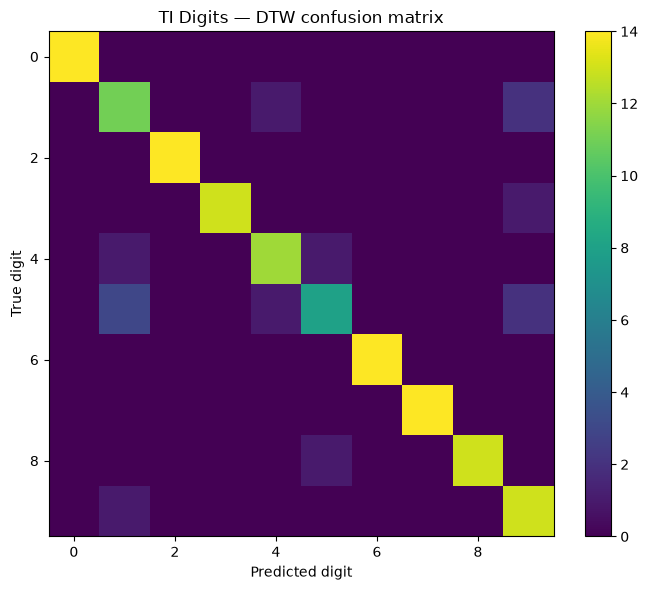

In [ ]:
classes=np.unique(np.concatenate([y_test,pred]))
cm=confusion_matrix(y_test, pred, labels=classes)
display(pd.DataFrame(cm,index=classes,columns=classes))
plt.figure(figsize=(7,6)); plt.imshow(cm,aspect="auto"); plt.colorbar(); plt.xlabel("Predicted digit"); plt.ylabel("True digit"); plt.title("TI Digits — DTW confusion matrix"); plt.tight_layout(); plt.show()
pd.DataFrame({"true":y_test,"predicted":pred}).to_csv(OUT/"ti_digits_dtw_predictions.csv",index=False)